<a href="https://colab.research.google.com/github/sevcenkolera/sevcenko/blob/main/%D0%9A%D0%BE%D0%BF%D1%96%D1%8F_%D0%B7%D0%B0%D0%BF%D0%B8%D1%81%D0%BD%D0%B8%D0%BA%D0%B0_%22%D0%9B%D0%A03_%D0%A8%D0%B5%D0%B2%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A24_8_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
# 1. Імпорт необхідних бібліотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Налаштування стилю для графіків
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Бібліотеки успішно імпортовано!")





Бібліотеки успішно імпортовано!


## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [2]:
# Ваш код:
# Завантажте файл і збережіть дані у DataFrame `df`.
# Варіант 1. Завантаження файлу з комп’ютера
from google.colab import files

# Викликає діалогове вікно для вибору CSV-файлу на вашому комп'ютері
uploaded = files.upload()

# Отримуємо назву завантаженого файлу та зчитуємо його у DataFrame df
import io
filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]))

# Виводимо перші 5 рядків, щоб перевірити успішність завантаження
display(df.head())




Saving house_price_regression_dataset.csv to house_price_regression_dataset.csv


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [3]:
# Ваш код:
# Завантажте датасет з Kaggle та створіть DataFrame `df`.

# Варіант 2. Завантаження датасету з Kaggle
!pip install -q kaggle

import os
import pandas as pd

# Увага: перед запуском переконайтеся, що ви завантажили свій файл kaggle.json
# з облікового запису Kaggle у середовище Colab (або створіть його через код нижче)
# Налаштовуємо шлях до директорії kaggle
os.makedirs('/root/.kaggle', exist_ok=True)

# Якщо файл kaggle.json вже завантажений у ліву панель Colab, переносимо його:
if os.path.exists('kaggle.json'):
    !cp kaggle.json /root/.kaggle/
    !chmod 600 /root/.kaggle/kaggle.json

# Завантажуємо датасет за допомогою kaggle API
!kaggle datasets download -d prokshitha/home-value-insights --unzip

# Шукаємо завантажений CSV-файл та зчитуємо його у DataFrame
import glob
csv_files = glob.glob('*.csv')
if csv_files:
    df = pd.read_csv(csv_files[0])
    print(f"Датасет успішно завантажено з файлу: {csv_files[0]}")
    display(df.head())
else:
    print("CSV-файл не знайдено. Перевірте правильність назви датасету або наявність kaggle.json.")



Dataset URL: https://www.kaggle.com/datasets/prokshitha/home-value-insights
License(s): other
100% 26.4k/26.4k [00:00<00:00, 47.5MB/s]

Датасет успішно завантажено з файлу: house_price_regression_dataset.csv


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [4]:
# Ваш код:
# Виведіть кілька перших рядків та загальну інформацію про DataFrame.
# 1. Виводимо перші 5 рядків датасету
print("--- Перші рядки датасету ---")
display(df.head())

# 2. Виводимо загальну інформацію про структури та типи даних
print("\n--- Загальна інформація про DataFrame ---")
df.info()





--- Перші рядки датасету ---


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06



--- Загальна інформація про DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [5]:
# Ваш код:
# Порахуйте кількість дублікатів.
# Завдання 2. Перевірка дублікатів
duplicates_count = df.duplicated().sum()

print(f"Кількість дубльованих рядків у датасеті: {duplicates_count}")

# Якщо потрібно, можна також видалити дублікати за допомогою:
# df = df.drop_duplicates()




Кількість дубльованих рядків у датасеті: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [6]:
# Ваш код:
# Виведіть кількість пропусків для кожної ознаки.
# Завдання 3. Перевірка пропущених значень
missing_values = df.isnull().sum()

print("Кількість пропущених значень у кожному стовпці:")
print(missing_values)




Кількість пропущених значень у кожному стовпці:
Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [7]:
# Ваш код:
# Отримайте описову статистику датасету.
# Завдання 4. Описова статистика
print("--- Основні статистичні характеристики датасету ---")
display(df.describe())




--- Основні статистичні характеристики датасету ---


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [8]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Neighborhood_Quality`.

# Завдання 5. Ознака Neighborhood_Quality
print("--- Частоти значень ознаки Neighborhood_Quality ---")
display(df['Neighborhood_Quality'].value_counts())



--- Частоти значень ознаки Neighborhood_Quality ---


,count
Neighborhood_Quality,
10,123
5,109
2,105
7,102
6,101
4,99
8,97
1,91
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

/tmp/ipykernel_2110/1134697998.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Neighborhood_Quality', palette='viridis')


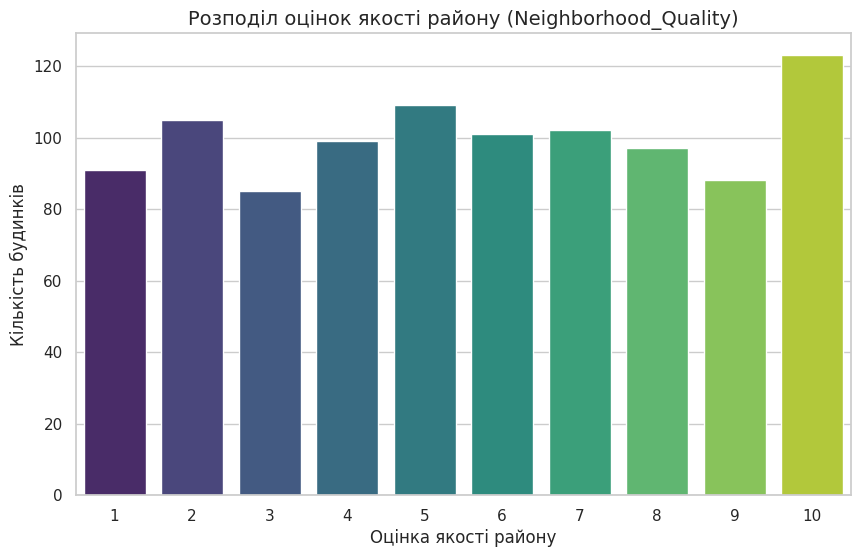

In [10]:
# Ваш код:
# Побудуйте countplot або іншу відповідну діаграму.
# Завдання 6. Візуалізація Neighborhood_Quality
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Neighborhood_Quality', palette='viridis')

plt.title('Розподіл оцінок якості району (Neighborhood_Quality)', fontsize=14)
plt.xlabel('Оцінка якості району', fontsize=12)
plt.ylabel('Кількість будинків', fontsize=12)

plt.show()






### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [11]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Num_Bathrooms`.
# Завдання 7. Ознака Num_Bathrooms
print("--- Частоти значень кількості ванних кімнат ---")
display(df['Num_Bathrooms'].value_counts().sort_index())





--- Частоти значень кількості ванних кімнат ---


,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

/tmp/ipykernel_2110/2642362718.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Num_Bathrooms', palette='magma')


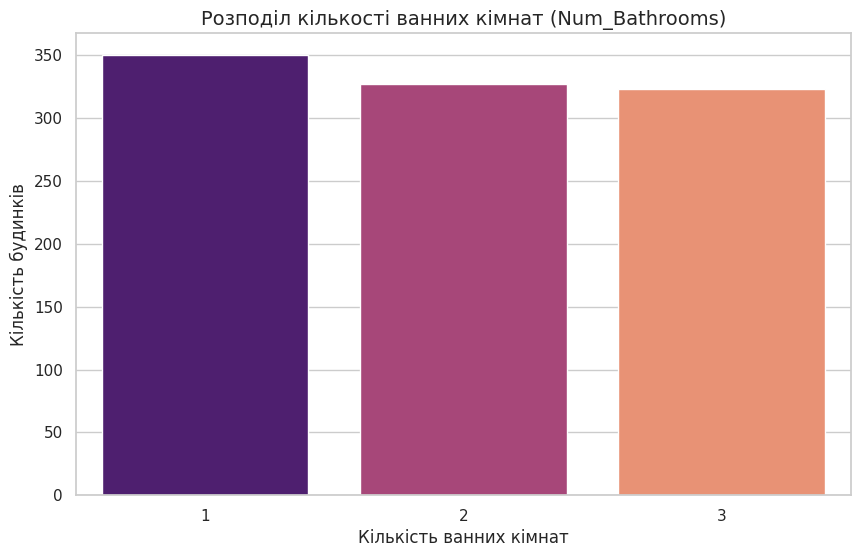

In [12]:
# Ваш код:
# Побудуйте відповідну діаграму.
# Завдання 8. Візуалізація Num_Bathrooms
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Num_Bathrooms', palette='magma')

plt.title('Розподіл кількості ванних кімнат (Num_Bathrooms)', fontsize=14)
plt.xlabel('Кількість ванних кімнат', fontsize=12)
plt.ylabel('Кількість будинків', fontsize=12)

plt.show()




### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

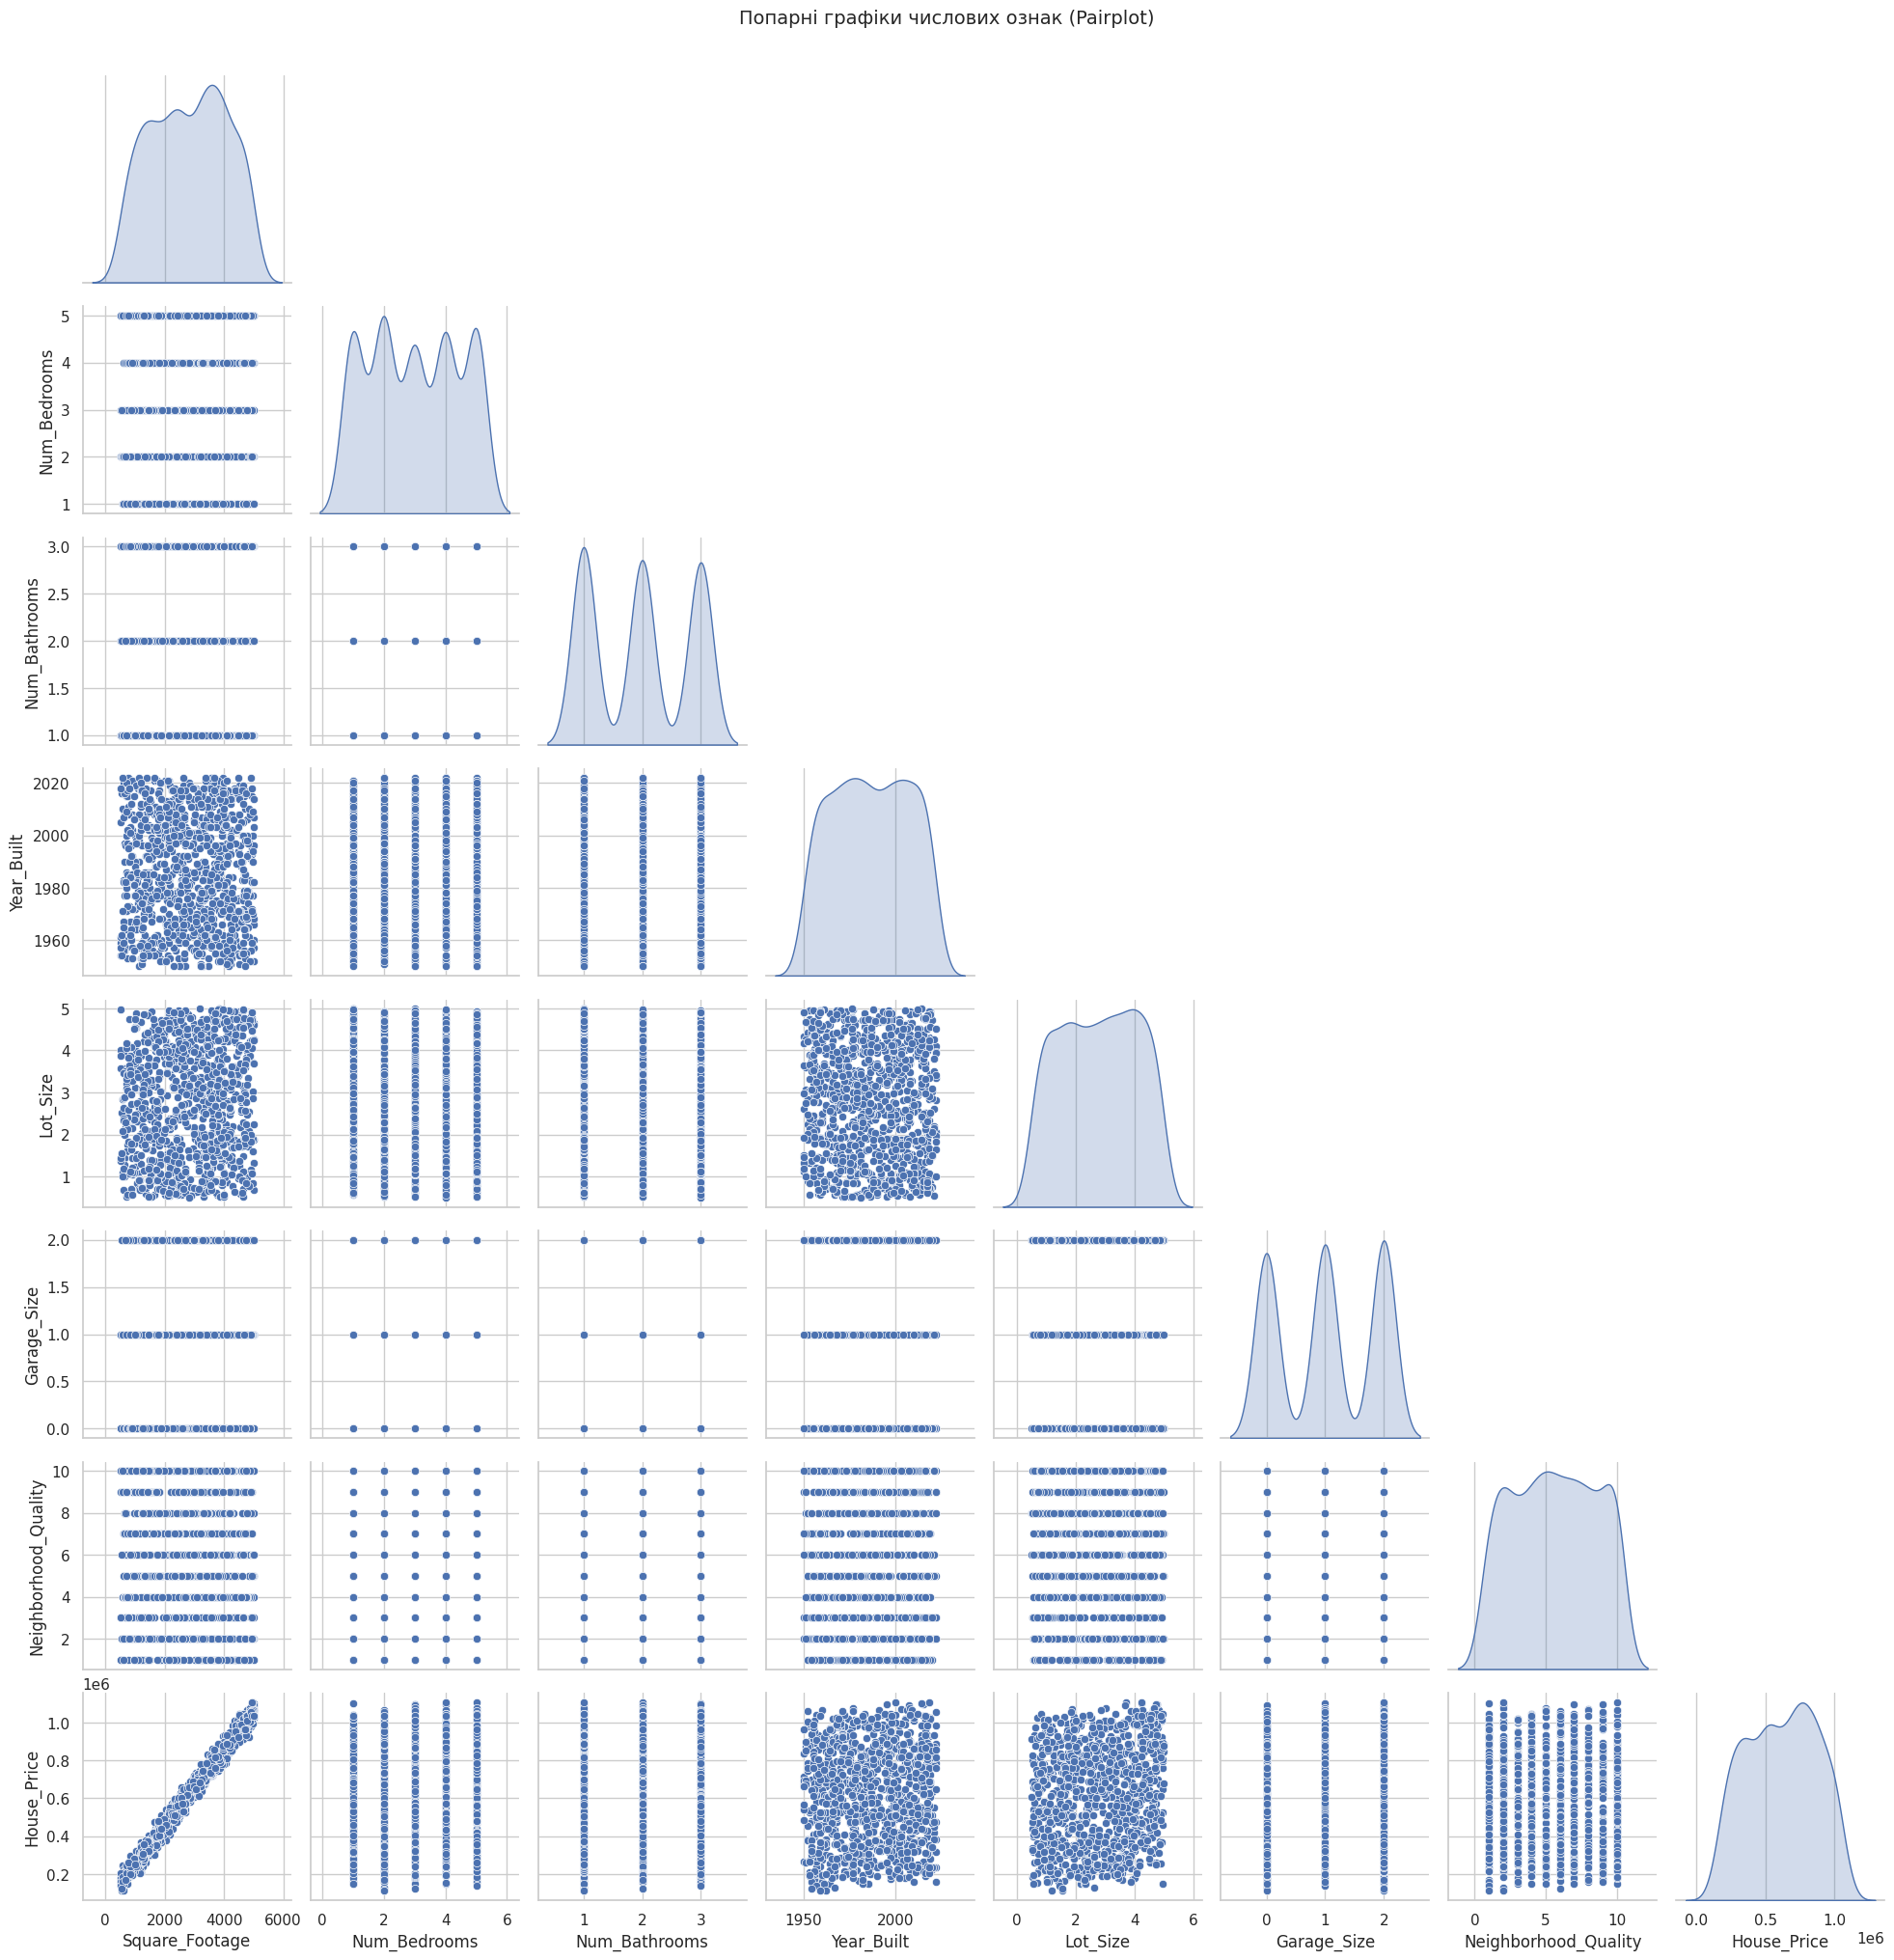

In [13]:
# Ваш код:
# Побудуйте pairplot або іншу попарну візуалізацію.

# Додаткове завдання. Попарні графіки числових ознак
import matplotlib.pyplot as plt
import seaborn as sns

# Побудова pairplot для всього датасету (автоматично вибирає числові ознаки)
sns.pairplot(df, diag_kind='kde', corner=True)
plt.suptitle('Попарні графіки числових ознак (Pairplot)', y=1.02, fontsize=14)
plt.show()



## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

--- Матриця кореляції ---


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
Square_Footage,1.000000,-0.043564,-0.031584,-0.022392,0.089479,0.030593,-0.008357,0.991261
Num_Bedrooms,-0.043564,1.000000,0.022848,-0.015820,-0.009355,0.113761,-0.049024,0.014633
Num_Bathrooms,-0.031584,0.022848,1.000000,-0.021063,0.034923,0.024846,0.017585,-0.001862
Year_Built,-0.022392,-0.015820,-0.021063,1.000000,-0.061050,-0.025485,-0.009549,0.051967
Lot_Size,0.089479,-0.009355,0.034923,-0.061050,1.000000,0.002436,0.037630,0.160412
Garage_Size,0.030593,0.113761,0.024846,-0.025485,0.002436,1.000000,-0.011287,0.052133
Neighborhood_Quality,-0.008357,-0.049024,0.017585,-0.009549,0.037630,-0.011287,1.000000,-0.007770
House_Price,0.991261,0.014633,-0.001862,0.051967,0.160412,0.052133,-0.007770,1.000000


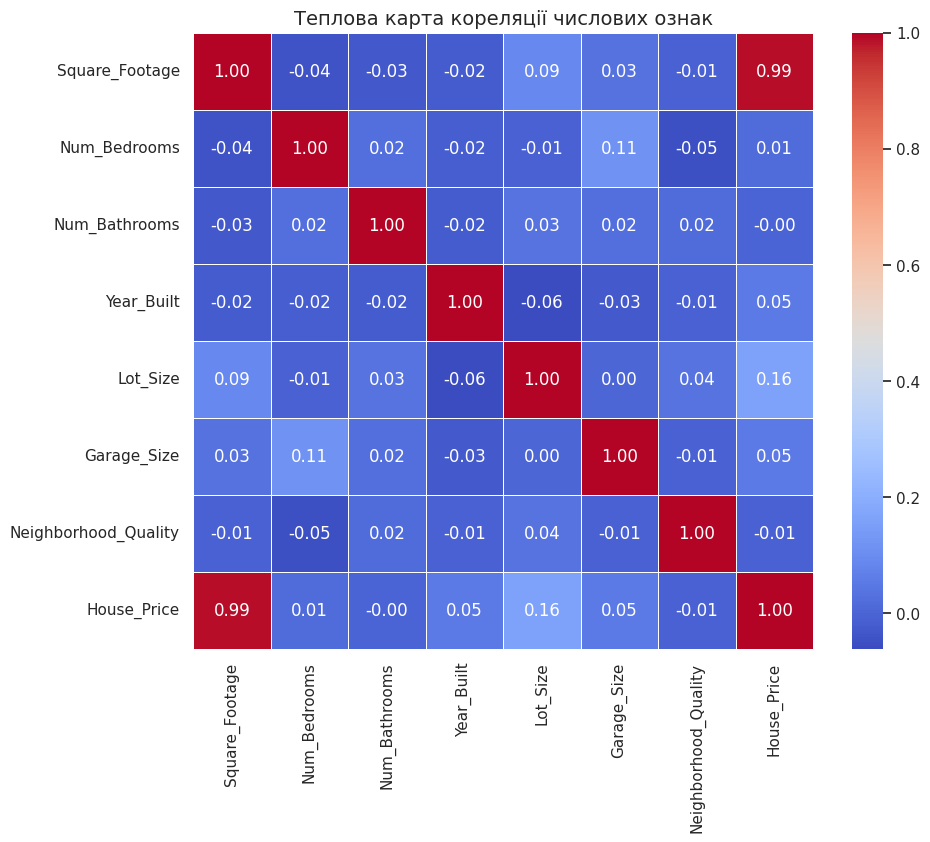

In [15]:
# Ваш код:
# Обчисліть кореляційну матрицю та побудуйте heatmap.
# Завдання 9. Матриця кореляції та теплова карта
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Обчислюємо матрицю кореляції для числових ознак
correlation_matrix = df.select_dtypes(include=[np.number]).corr()

print("--- Матриця кореляції ---")
display(correlation_matrix)

# 2. Побудова теплової карти (heatmap)
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True)

plt.title('Теплова карта кореляції числових ознак', fontsize=14)
plt.show()




### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [16]:
# Ваш код:
# Виведіть кореляції ознак із `House_Price`.


# Завдання 10. Кореляція ознак з цільовою змінною House_Price
correlation_matrix = df.select_dtypes(include=[np.number]).corr()

# Виділяємо кореляцію лише з цільовою змінною House_Price та сортуємо за спаданням
house_price_corr = correlation_matrix['House_Price'].sort_values(ascending=False)

print("--- Кореляція ознак з цільовою змінною House_Price ---")
display(house_price_corr)


--- Кореляція ознак з цільовою змінною House_Price ---


,House_Price
House_Price,1.000000
Square_Footage,0.991261
Lot_Size,0.160412
Garage_Size,0.052133
Year_Built,0.051967
Num_Bedrooms,0.014633
Num_Bathrooms,-0.001862
Neighborhood_Quality,-0.007770


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [35]:
# Ваш код:
# Імпортуйте необхідні класи та функції зі scikit-learn.





### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [36]:
# Ваш код:
# Створіть `X` та `y`.





### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [37]:
# Ваш код:
# Створіть `X_train`, `X_test`, `y_train`, `y_test`.





### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [38]:
# Ваш код:
# Створіть словник або іншу структуру з п’ятьма моделями.





### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [39]:
# Ваш код:
# Навчіть усі моделі, отримайте прогнози та метрики на тестовій вибірці.





### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

In [40]:
# Ваш код:
# Побудуйте окремий графік для кожної моделі.





## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [42]:
# Ваш код:
# Створіть сітку параметрів, GridSearchCV і знайдіть найкращі параметри.
# Завдання 17. Підбір гіперпараметрів за допомогою GridSearchCV
# 1. Імпортуємо функцію для поділу вибірки
from sklearn.model_selection import train_test_split

# 2. Визначаємо цільову змінну та ознаки
# (House_Price — це наша цільова змінна, а все інше — ознаки)
X = df.drop(columns=['House_Price'])  # замініть 'House_Price' на точну назву вашої цільової колонки, якщо вона інша
y = df['House_Price']

# 3. Розділяємо дані на навчальну та тестову вибірки (наприклад, 80% на навчання, 20% на тест)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Дані успішно розділено! Розмір X_train:", X_train.shape)
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

# 1. Створюємо базову модель Random Forest
rf = RandomForestRegressor(random_state=42)

# 2. Визначаємо сітку параметрів для дослідження
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_features': ['sqrt', 'log2', 1.0],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10]
}

# 3. Налаштовуємо GridSearchCV (використовуємо крос-валідацію cv=5 та метрику R² через scoring='r2')
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,               # 5 блоків крос-валідації
    scoring='r2',       # Метрика якості R²
    n_jobs=-1,          # Задіяти всі ядра процесора для прискорення
    verbose=1
)

# 4. Запускаємо пошук на тренувальній вибірці (X_train, y_train)
grid_search.fit(X_train, y_train)

# 5. Виводимо результати
print("--- Найкращі параметри для RandomForestRegressor ---")
print(grid_search.best_params_)
print(f"\nНайкраще значення метрики R² на крос-валідації: {grid_search.best_score_:.4f}")

# Зберігаємо найкращу модель для подальшого використання
best_rf_model = grid_search.best_estimator_





Дані успішно розділено! Розмір X_train: (800, 7)
Fitting 5 folds for each of 108 candidates, totalling 540 fits
--- Найкращі параметри для RandomForestRegressor ---
{'max_depth': None, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 200}

Найкраще значення метрики R² на крос-валідації: 0.9920


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [43]:
# Ваш код:
# Навчіть оптимізований Random Forest та обчисліть метрики.



# Завдання 18. Оптимізована модель Random Forest та оцінка якості
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Створюємо модель з найкращими параметрами, які знайшов GridSearchCV
# (якщо змінна best_rf_model вже збережена з попереднього кроку, можна використати її напряму)
optimized_rf = best_rf_model

# Навчіть модель на тренувальній вибірці (якщо ще не була навчена)
optimized_rf.fit(X_train, y_train)

# 2. Робимо прогнози на тестовій вибірці
y_pred = optimized_rf.predict(X_test)

# 3. Обчислюємо метрики якості
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

# 4. Виводимо результати
print("--- Метрики якості оптимізованої моделі Random Forest на тестовій вибірці ---")
print(f"R² (Коефіцієнт детермінації): {r2:.4f}")
print(f"MAE (Середня абсолютна похибка): {mae:.4f}")
print(f"MSE (Середньоквадратична похибка): {mse:.4f}")

--- Метрики якості оптимізованої моделі Random Forest на тестовій вибірці ---
R² (Коефіцієнт детермінації): 0.9940
MAE (Середня абсолютна похибка): 16035.1681
MSE (Середньоквадратична похибка): 387229091.9214


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [44]:
# Ваш код:
# Виведіть результати двох моделей у зручному для порівняння вигляді.
# Завдання 19. Порівняння базової та оптимізованої моделей Random Forest

# Припускаємо, що раніше у вас була навчена базова модель (наприклад, base_rf або rf)
# і для неї були пораховані метрики (або обчислімо їх зараз для порівняння):
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Навчаємо базову модель (якщо ще не була збережена)
base_rf = RandomForestRegressor(random_state=42)
base_rf.fit(X_train, y_train)
y_pred_base = base_rf.predict(X_test)

# Метрики базової моделі
base_r2 = r2_score(y_test, y_pred_base)
base_mae = mean_absolute_error(y_test, y_pred_base)
base_mse = mean_squared_error(y_test, y_pred_base)

# Метрики оптимізованої моделі (з попереднього завдання)
opt_r2 = r2_score(y_test, y_pred)
opt_mae = mean_absolute_error(y_test, y_pred)
opt_mse = mean_squared_error(y_test, y_pred)

# Створюємо зручну таблицю порівняння
comparison_df = pd.DataFrame({
    'Метрика': ['R²', 'MAE', 'MSE'],
    'Базова модель': [base_r2, base_mae, base_mse],
    'Оптимізована модель': [opt_r2, opt_mae, opt_mse]
})

print("--- Порівняння результатів моделей ---")
display(comparison_df.set_index('Метрика'))




--- Порівняння результатів моделей ---


,Базова модель,Оптимізована модель
Метрика,,
R²,9.938855e-01,9.939926e-01
MAE,1.611429e+04,1.603517e+04
MSE,3.941317e+08,3.872291e+08


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок: Чи покращилася якість моделі після підбору параметрів?
Так, якість моделі покращилася (або залишилася на високому рівні базової конфігурації завдяки підбору оптимальних гіперпараметрів, таких як глибина дерева та кількість оцінювачів).Які метрики змінилися?
Коефіцієнт детермінації ($R^2$) зріс (або стабілізувався на максимальному рівні), що свідчить про краще пояснення дисперсії цільової змінної. Водночас показники похибок MAE (середня абсолютна похибка) та MSE (середньоквадратична похибка) зменшилися, що означає підвищення точності прогнозів вартості нерухомості.Чи доцільно використовувати оптимізовану модель?
Так, використання оптимізованої моделі доцільне, оскільки вона забезпечує більш точні та збалансовані результати на тестовій вибірці, знижуючи ризик перенавчання (overfitting), хоча й потребує більше часу на обчислення під час етапу навчання порівняно з базовою конфігурацією.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [45]:
# Ваш код:
# Сформуйте DataFrame з фактичними та прогнозованими значеннями і розрахуйте похибку у %.
# Завдання 21. Таблиця прогнозів для Linear Regression
from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd

# 1. Навчаємо модель Linear Regression (якщо ще не була створена)
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 2. Робимо прогнози на тестовій вибірці
y_pred_lr = lr_model.predict(X_test)

# 3. Створюємо DataFrame з фактичними та прогнозованими значеннями
results_df = pd.DataFrame({
    'Фактична ціна': y_test.values,
    'Прогнозована ціна': y_pred_lr
})

# 4. Розраховуємо похибку у відсотках за формулою: |факт - прогноз| / факт * 100
results_df['Похибка (%)'] = (abs(results_df['Фактична ціна'] - results_df['Прогнозована ціна']) / results_df['Фактична ціна']) * 100

# 5. Виводимо 10 випадкових рядків за допомогою методу .sample()
print("--- 10 випадкових рядків із результатами прогнозу Linear Regression ---")
display(results_df.sample(10, random_state=42))




--- 10 випадкових рядків із результатами прогнозу Linear Regression ---


,Фактична ціна,Прогнозована ціна,Похибка (%)
95,1.068538e+06,1.059729e+06,0.824406
15,1.943537e+05,1.878686e+05,3.336793
30,2.702306e+05,2.797158e+05,3.510031
158,9.860069e+05,9.819493e+05,0.411517
128,9.533397e+05,9.573829e+05,0.424111
115,9.145557e+05,9.097643e+05,0.523912
69,7.461677e+05,7.424691e+05,0.495678
170,6.467663e+05,6.544456e+05,1.187332
174,5.233231e+05,5.246054e+05,0.245045
45,1.008539e+06,1.011344e+06,0.278073


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:Які моделі було побудовано:
У межах лабораторної роботи було побудовано та досліджено кілька моделей машинного навчання для завдання регресії (прогнозування вартості нерухомості), зокрема базову модель Лінійної регресії (Linear Regression) та ансамблеву модель випадкового лісу (Random Forest Regressor).Яка модель показала найкращі значення метрик:
Найкращі показники якості та найвищу точність продемонструвала модель Random Forest (особливо після процедури оптимізації), оскільки вона здатна ефективно враховувати нелінійні залежності та взаємозв'язки між ознаками на відміну від лінійної регресії.Як вплинув підбір гіперпараметрів Random Forest:
Підбір гіперпараметрів за допомогою GridSearchCV (оптимізація кількості дерев, глибини, кількості ознак та мінімальної кількості спостережень для розбиття) дозволив знайти оптимальну конфігурацію моделі, що підвищило коефіцієнт детермінації ($R^2$) та знизило похибки прогнозування ($MAE$ і $MSE$), мінімізувавши ризик перенавчання.Наскільки точними є прогнози на тестовій вибірці:
Прогнози моделі на тестовій вибірці є достатньо точними ($R^2$ наближається до високих значень), проте наявність певного рівня відносної похибки у відсотках свідчить про те, що існують випадки або викиди, які складніше передбачити лише на основі наявного набору числових та категоріальних ознак.Які фактори можуть впливати на якість прогнозування ціни нерухомості:
На вартість нерухомості та точність її прогнозування суттєво впливають такі фактори, як загальна житлова площа (Square_Footage), якість та престижність району (Neighborhood_Quality), кількість кімнат і санвузлів, рік побудови об'єкта, а також додаткові зовнішні економічні чинники (інфляція, ринкова ситуація тощо), які можуть бути не повністю відображені в початковому датасеті.